# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [3]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print(users.isna().sum()) # Cantidad de valores nulos)
print(users.isna().mean()) # Proporción de valores nulos)

user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print(usage.isna().sum())
print(usage.isna().mean())

id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
  R: En el df 'users' la columna 'city' muestra un 11.72% de valores NaN y la columna 'churn_date' un 88.35%.
  En el df 'usage' la colmuna 'date' muestra un 0.12% de valores NaN, y las columnas 'duration' y 'length' muestran un 55.19% y 44.74% de valores NaN
- Indica qué harías: ¿imputar, eliminar, ignorar?
  R: En el df 'users' hay que investigar los valores NaN de la columna 'city', para decidir sobre imptuación o dejar nulos. En la columna 'churn_date' ignoramos los valores NaN, ya que esta nos indica la permanencia de los clientes.
  En el df 'usage' eliminaremos los valores NaN de la columna 'date', para poder tener un mejor análisis de los datos, y en las columnas 'duration' y 'length' ignoramos los valores NaN.

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users
users[['user_id', 'age']].describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` cuenta con 4000 registros, no tiene valores NaN, los datos están completos y son confiables  "Haz doble clic en este bloque y escribe qué ves".
- La columna `age` observamos la presencia de valores '-999', que no deberian de existir y que afectan los resultados en el análisis estadístico al calcular promedio y std.

In [13]:
# explorar columnas numéricas de usage
usage[['id', 'user_id', 'duration', 'length']].describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id` muestran datos completos y confiables. Estas columnas nos muestran valores únicos para cada cliente y registro de llamadas o mensajes enviados.   "Haz doble clic en este bloque y escribe qué ves".
- Las columnas `duration` y `lenght` nos indican cuantas veces un cliente realizó una llamada o mensaje y la duración o longitud de los mismos, muestran datos completos y confiables.

In [14]:
# explorar columnas categóricas de users
columnas_user = users[['city', 'plan']]
columnas_user.describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` cuenta con 3531 valores, lo que indica que hacen falta 469 (aproximadamente el 11%) datos. Nos muestra un total de 7 ciudades diferentes y la más frecuente es Bogotá, con 808 registros. Hay que analizar la columna para estandarizar los nombres de las ciudades y descartar posibles sesgos en la medición estadística.
- La columna `plan` cuenta con los datos completos, con 2 unicos planes y el más frecuente es el plan Básico con 2592 registros.

In [15]:
# explorar columna categórica de usage
usage['type'].describe() # completa el código

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

- La columna `type` contiene datos completos, 2 unicos tipos de datos y el más frecuente es 'text', con 22092 registros


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
   En el df 'users' se detectó en la columna 'age' valores inválidos de '-999'. En la columna 'city' falta aproximadamente el 11% de los datos.
   En el df 'usage' no se han detectado datos inválidos que puedan generar algún problema en el análisis, por lo que los datos de este dataset son confiables.
- ¿Qué acción tomarías?
  Para el caso del dataset 'user', en la columna 'age' primero hay que revisar cuántos valores existen de '-999', si el porcentaje no es mayor a 5%, podemos tomar la decisión de eliminarlos o imputar con la mediana. En caso de que exista un porcentaje mayor al 6%, habrá que tomar una decisión de imputar con la mediana para tener un mejor análsis. Para la columna 'city', primero hay que asegrarnos que los nombres de las ciudades estén estandarizados y después realizar una imputación de los datos faltantes con NA para mantener completa la información a analizar.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date']) # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date']) # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].value_counts()

2026-05-10 00:00:00.000000000    40
2023-12-20 18:33:45.506376600     1
2022-11-21 17:58:06.571642912     1
2024-06-20 09:50:54.463615904     1
2022-05-22 00:23:45.956489122     1
                                 ..
2022-07-29 04:44:06.661665416     1
2022-02-22 00:36:43.750937734     1
2022-10-31 09:22:49.242310580     1
2022-09-24 16:46:48.702175544     1
2022-03-28 12:38:20.975243811     1
Name: reg_date, Length: 3961, dtype: int64

En `reg_date`, existen 40 valores con año 2026, lo que representa el 1% respecto del total, podemos tomar la decisión de eliminar esos registros.
"haz doble clic en este bloque y escribe qué ves".

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].value_counts()

2024-06-16 13:26:59.770494262    1
2024-06-21 22:28:11.862296556    1
2024-06-06 11:09:26.204155102    1
2024-04-14 16:05:21.848046200    1
2024-04-01 14:39:43.079576989    1
                                ..
2024-04-13 22:49:17.653941348    1
2024-03-06 03:52:44.749118728    1
2024-03-21 23:20:13.140328508    1
2024-01-07 00:52:33.678841971    1
2024-04-08 01:44:47.917197929    1
Name: date, Length: 39950, dtype: int64

En `date`, los datos son más precisos y consistentes, podemos observar que no existen fechas futuras.  
"haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas".

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos). En el dataset 'users' en la columba 'reg_date' aparecen 40 registros con el año 2026, equivalente al 1% respecto del total.
  En el dataset 'usage', en la columna 'date' no existen fechas despues de 2024, por lo que los datos son más confiables.
- ¿Qué harías con ellas?
  En el caso de la columna 'reg_date' del dataset 'usuarios', podemos tomar la decisión de descartarlas para el análisis, pues no nos aportan información confiable.
  En el caso del dataset 'usage' la columna 'date' contiene datos más confiables para poder usarlos en el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace("?", pd.NA)

# Verificar cambios
users['city'].describe()

count       3435
unique         6
top       Bogotá
freq         808
Name: city, dtype: object

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'] > '2024-12-31', 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].describe()

count                              3960
unique                             3960
top       2024-06-27 06:08:22.325581392
freq                                  1
first               2022-01-01 00:00:00
last                2024-12-31 00:00:00
Name: reg_date, dtype: object

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).mean()

type
call    0.000000
text    0.999276
Name: duration, dtype: float64

In [24]:
# Verificación MAR en usage (Missing At Random) para length
usage['length'].isna().groupby(usage['type']).mean()

type
call    0.99933
text    0.00000
Name: length, dtype: float64

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
Hay una concentración alta de valores faltantes de 'duration' y 'length' en la columna 'type', por lo que podemos afirmar que son **MAR**.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id')[['is_text', 'is_call', 'duration']].sum().reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text':'cant_mensajes', 'is_call':'cant_llamadas',
    'duration':'cant_minutos_llamada'})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on = 'user_id')
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.124531,5.524381,4.478120,23.317054
std,1154.898108,17.692032,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,4.000000,3.000000,11.120000
50%,12000.000000,47.000000,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize=True)*100


Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

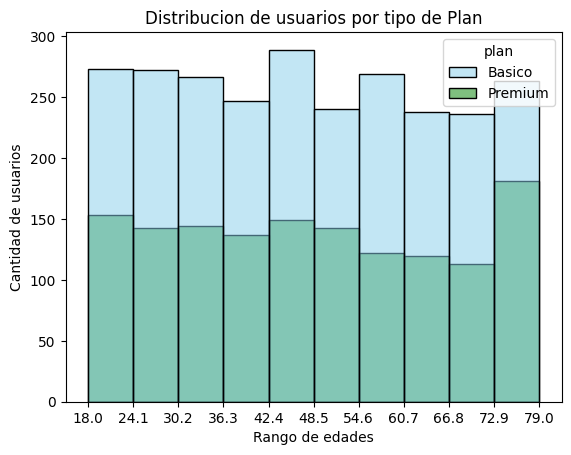

In [30]:
# Histograma para visualizar la edad (age)
bins_age = np.histogram_bin_edges(user_profile['age'], bins=10)
sns.histplot(data=user_profile, x='age', bins=bins_age, hue='plan', palette=['skyblue', 'green'])
plt.xticks(bins_age)
plt.xlabel('Rango de edades')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de usuarios por tipo de Plan')
plt.show()

💡Insights: 
- Existe una distribución uniforme de manera general entre ususarios con plan Basico y usuarios con plan Premium, sin embargo, podemos notrar claramente que la mayor proporción de plan Premium respecto al plan Basico, se encuentra en los usuarios con rango de edad de 73 a 79 años, adultos mayores, seguido del otro segmento de 49 a 54 años de edad, tambien se observa una mayor proporción de plan Premium respecto al plan Basico.
- De igual manera, podemos observar que la mayor cantidad de usuarios se encuentra en un rango de edad de 43 a 48 años de edad, con una proporción aproximadamente igual entre usuarios con plan Basico y plan Premium.

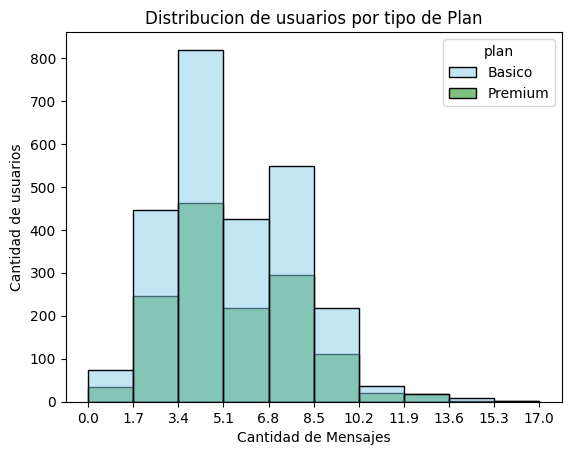

In [31]:
# Histograma para visualizar la cant_mensajes
bins_mensajes = np.histogram_bin_edges(user_profile['cant_mensajes'], bins=10)
sns.histplot(data=user_profile, x='cant_mensajes', bins=bins_mensajes, hue='plan', palette=['skyblue', 'green'])
plt.xticks(bins_mensajes)
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de usuarios por tipo de Plan')
plt.show()

💡Insights: 
-Podemos observar que la mayoria de los usuarios envian de 2 a 10 mensajes por mes en ambos planes, Premium y Basico. No se observa una tendencia clara entre usuarios Premium y con plan Basico. En general, ambos usuarios envías aproximadamente la misma cantidad de mensajes.
-También podemos observar que la mayoria de los usuarios envian entre 4 a 5 mensajes por mes.

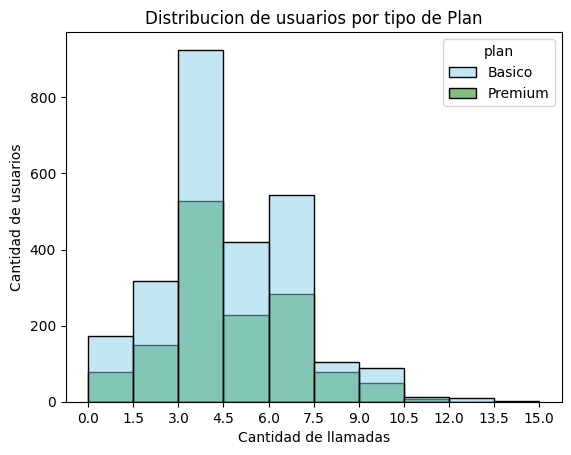

In [32]:
# Histograma para visualizar la cant_llamadas
bins_llamadas = np.histogram_bin_edges(user_profile['cant_llamadas'], bins=10)
sns.histplot(data=user_profile, x='cant_llamadas', bins=bins_llamadas, hue='plan', palette=['skyblue', 'green'])
plt.xticks(bins_llamadas)
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de usuarios por tipo de Plan')
plt.show()

💡Insights:
- Al igual que con los mensajes, la distribución entre ususarios Premium y con plan Basico es más o menos sismilar en cuanto a la cantidad de llamadas realizadas por mes, ambos tipos de usuarios, realizan entre 0 a 10 llamadas por mes.
- Se observa tambien que la mayoria de los usuarios realizan entre 3 a 4 llamadas por mes, tanto con plan Premium como Basico.

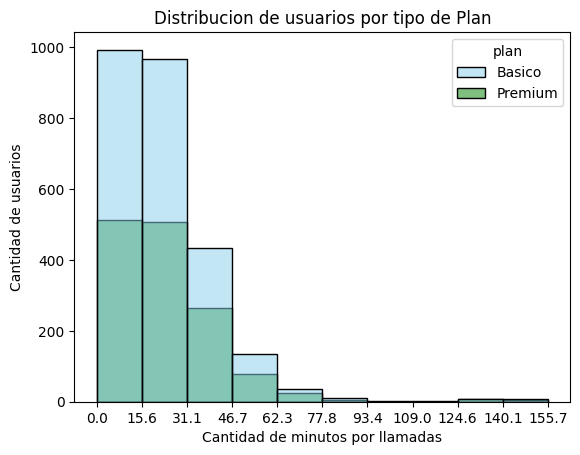

In [33]:
# Histograma para visualizar la cant_minutos_llamada
bins_minutos = np.histogram_bin_edges(user_profile['cant_minutos_llamada'], bins=10)
sns.histplot(data=user_profile, x='cant_minutos_llamada', bins=bins_minutos, hue='plan', palette=['skyblue', 'green'])
plt.xticks(bins_minutos)
plt.xlabel('Cantidad de minutos por llamadas')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de usuarios por tipo de Plan')
plt.show()

💡Insights: (sesgo right-skewed)
-Observamos claramente que la mayoria de los usuarios realizan llamadas con una duración entre 0 a 15 minutos, con una proporcion similar a usuarios que realizan llamadas que duran entre 15 a 30 minutos.
-No se distingue una proporción considerable entre usuarios Premium y con plan Basico en cuanto a la duración de las llamadas.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

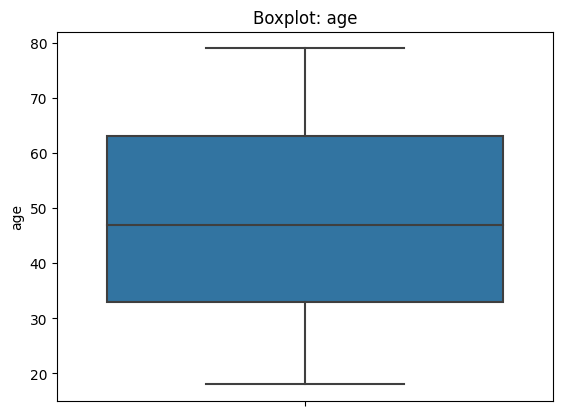

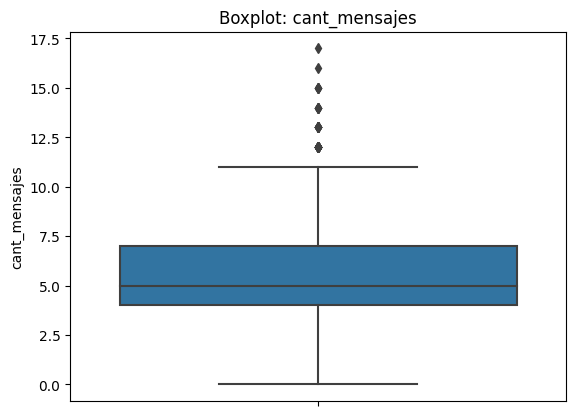

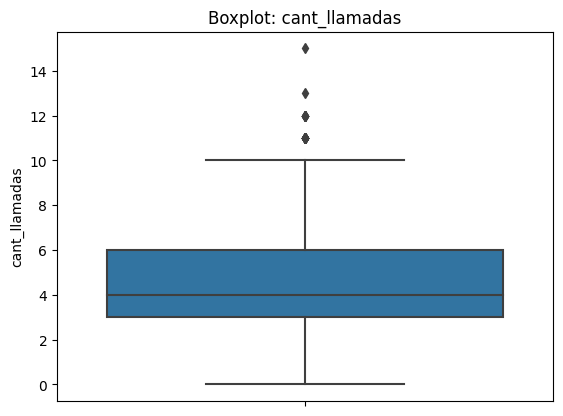

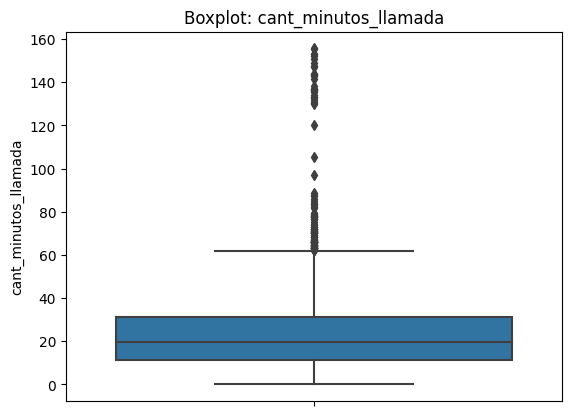

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
   sns.boxplot(data=user_profile, y=col)
   plt.title(f'Boxplot: {col}')
   plt.show()

💡Insights: 
- Age: observamos que la columna 'age' no presenta outliers y el 50 porciento de los usuarios se encuentran en el rango de edad de 33 a 63 años, aproximadamente.
- cant_mensajes: Observamos la presenca de 6 outliers, de un solo lado.
- cant_llamadas: Podemos observar la presencia de 4 outliers, de un solo lado.
- cant_minutos_llamada: En esta coclumna podemos observar una cantidad muy grande de outliers, llamadas que duran mas de 60 minutos, estos outliers se encuentran de un solo lado.

In [35]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
  Q1=user_profile[col].quantile(0.25)
  Q3=user_profile[col].quantile(0.75)
  IQR=Q3-Q1
  print(col, "IQR:", IQR, "Q3:", Q3)
  upper = Q3+1.5*IQR
  #display(user_profile[user_profile[col]>upper])

cant_mensajes IQR: 3.0 Q3: 7.0
cant_llamadas IQR: 3.0 Q3: 6.0
cant_minutos_llamada IQR: 20.295 Q3: 31.415


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantenemos los outliers, ya que son clientes reales.
- cant_llamadas: mantener o no outliers, porqué? Mantenemos los outliers, ya que esto puede representar un negocio potencial para ofrecer algún plan especial a los usuarios que realizan más llamadas.
- cant_minutos_llamada: mantener o no outliers, porqué? Mantenemos los outliers, ya que puede haber un segmento especifico de clientes reales a quienes podemos ofrecerles algún plan u oferta especial para minutos en llamadas.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [37]:
# Crear columna grupo_uso
def clasificar_usuarios(row):
    llamadas = row['cant_llamadas']
    mensajes = row['cant_mensajes']
    if pd.isna(llamadas) or pd.isna(mensajes):
        return "Error en datos"
    if llamadas < 5 and mensajes <5:
        return "Bajo uso"
    elif llamadas <10 and mensajes <10:
        return "Uso medio"
    else:
        return "Alto uso"

user_profile['grupo_uso']=user_profile.apply(clasificar_usuarios, axis=1)

In [38]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [39]:
# Crear columna grupo_edad
def edad_usuarios(row):
    edad = row['age']
    if pd.isna(edad):
        return "Error en datos"
    if edad <30:
        return "Joven"
    elif edad <60:
        return "Adulto"
    else:
        return "Adulto mayor"

user_profile['grupo_edad']=user_profile.apply(edad_usuarios, axis=1)

In [40]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

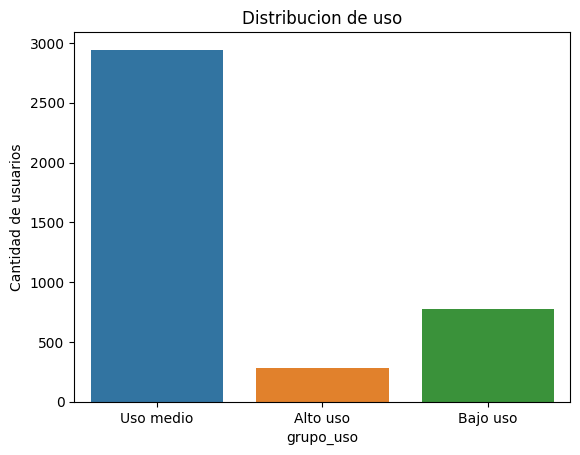

Uso medio    73.593398
Bajo uso     19.454864
Alto uso      6.951738
Name: grupo_uso, dtype: float64


In [41]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de uso')
plt.show()
print(user_profile['grupo_uso'].value_counts(normalize=True)*100)

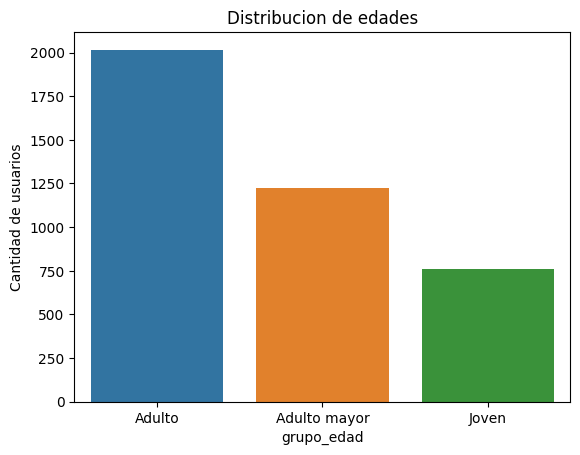

Adulto          50.437609
Adulto mayor    30.557639
Joven           19.004751
Name: grupo_edad, dtype: float64


In [42]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de edades')
plt.show()
print(user_profile['grupo_edad'].value_counts(normalize=True)*100)

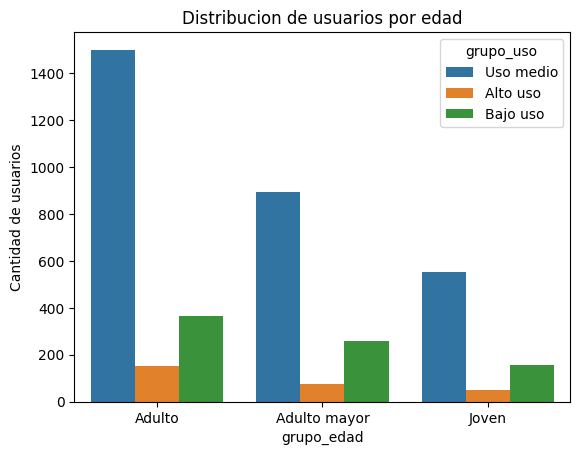

grupo_uso     Alto uso   Bajo uso  Uso medio
grupo_edad                                  
Adulto        7.585523  18.046604  74.367873
Adulto mayor  6.055646  21.031097  72.913257
Joven         6.710526  20.657895  72.631579


In [46]:
sns.countplot(data=user_profile, x='grupo_edad', hue='grupo_uso')
plt.ylabel('Cantidad de usuarios')
plt.title('Distribucion de usuarios por edad')
plt.show()

tabla_pct = pd.crosstab(user_profile['grupo_edad'], user_profile['grupo_uso'], normalize='index') * 100
print(tabla_pct)
#print(user_profile['grupo_edad'].value_counts(normalize=True)*100)


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?
  En el dataset 'users', la columna 'city' tiene un 11% de NA, sin embargo, en esta ocasión no analizamos ciudades. la columna 'reg_date' se cambio a formato 'datetime', de igual manera contenia 40 filas con años erroneos, fechas de 2026. La columba 'age' presentaba datos inválidos que se sustituyeron por NA.
  En el dataset 'usage', la columna 'date' se cambio a formato 'datetime' y hacian falta 50 valores, es decir, aproximadamente el 0.1% respecto del total, por lo que estadísticamente, no es significativo y no hay mucha variabilidad de los datos al analizarlos.

- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  Se segmentaron los clientes en 3 categorias, "Joven", "Adulto" y "Adulto mayor". La mayoria de los usuarios se encuentran en la categoria "Adulto", con un rango de edad de entre 30 y 60 años, aproximadamente 2,000 usuarios. Tambien se segmentaron los clientes de acerdo al uso del plan en tres categorias "Bajo uso", "Uso medio" y "Alto uso" y la mayoria de los clientes (aproimadamente 3,000) hace un "Medio uso" del plan, esto quiere decir, que realizan entre 5 a 10 llamadas y/o mensajes por mes.
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué? El segmento más importante de acuerdo a la edad de los usuarios es "Adulto" (aproximadamente el 50% de usuarios), con edades entre 30 y 60 años, segido por "Adulto mayor", con edades mayores a los 60 años. Estos dos segmentos representan alrededor del 80% del total de usuarios de ConnectaTel
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?
   La mayor cantidad de uso extremo se encontro en la cantidad de minutos por llamadas ('cant_minutos_llamada'), hay una tendencia normal en llamadas que duran entre 1 a 15 minutos, sin embargo, se encontraron usuarios que realizaban llamadas con una duración mayo a los 60 minutos, inclusive, el valor máximo registrado de duración de una llamada, fue de 177 minutos. Anque no es un segmento amplio de usuarios, se puede ofrecer un plan especial para los usuarios que realizan llamadas de larga duración.

- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?
   Crear un nuevo plan "VIP" para aquellos usuarios de "Alto uso" en donde se puedan incluir minutos en llamadas y mensajes, ambos ilimitados.
   Lanzar campaña de promoción de descuento en plan "Premium" para que mas usuarios puedan adquirirlo.
   Inlcuir promoción en uso de "redes sociales" para que más jóvenes adquieran algún tipo de plan.

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Valores que no deberian de existir como '-999' y '?' en dataframes 'users' y 'usage'
- Columnas 'date' sin formato 'datetime' en dataframes 'users'y 'usage'.
- Valores nulos en columnas 'city', 'reg_date' y 'date' que podrian complicar el análisis.


🔍 **Segmentos por Edad**
- El 50.44% de los usuarios tienen una edad entre 30 y 60 años (categoria "Adulto")
- El 30.56% de los usuarios tienen una edad mayor a 60 años (Categoria "Adulto mayor")
- El 81% de los usuarios del ConnectaTel son adultos mayores de 30 años.
- Tan sólo el 19% de ususarios entran en la categoria de "Joven", con rango de edad menor a 30 años.


📊 **Segmentos por Nivel de Uso**
- El 73.6% de los usuarios hacen un "Uso medio" del plan, es decir, entre 5 a 10 llamadas y/o minutos por mes.
- El 19.45% de los usuarios hacen un "Bajo uso" del plan, es decir, menos de 5 llamadas y/o mensajes por mes.
- El 6.95% de los usuarios hacen un "Alto uso" del plan, mas de 10 mensajejs y/o llamadas por mes.


➡️ Esto sugiere que 
- La mayor cantidad de usuarios son Adultos mayores de 30 y existe una proporcion de usuarios mas o menos similar entre grupo de edad y uso del plan.
- El 64.86% de los usuarios cuentan con un plan 'Basico'.


💡 **Recomendaciones**
- Lanzar campañas de promoción o descuentro en plan 'Premium' para que más usuarios puedan adquirirlo.
- Poner a prueba un nuevo plan 'VIP' para aquellos usuarios de 'Alto uso'.
- Inluir promocion de uso de 'redes sociales' ilimitadas para atraer a más jóvenes.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`